In [33]:
import numpy as np

np.random.seed(42)

#generate the composition of soil
sand = np.random.uniform(0, 100, 1000)
clay = np.random.uniform(0, 100-sand, 1000)
silt = 100 - sand - clay

#generate the properties of soil
ph = np.random.uniform(4, 9, 1000)
organic_matter = np.random.uniform(0, 10, 1000)

#combine them
X = np.column_stack([
    sand, silt, clay, ph, organic_matter
])

print(X)

[[37.45401188 50.96666615 11.57932197  5.30852842  6.72702994]
 [95.07143064  2.25777295  2.6707964   5.234894    7.96681397]
 [73.19939418  3.40512857 23.39547725  8.5312729   2.50467899]
 ...
 [13.68186309 80.36580941  5.9523275   5.5489393   3.94572315]
 [95.02373538  4.69234523  0.28391939  5.45022766  5.29940587]
 [44.6005773  39.76642167 15.63300103  8.35707017  1.61367358]]


In [34]:
labels = []

for i in range(len(X)):
    if clay[i] >= 40:
        labels.append(0)       # Clay
    elif sand[i] >= 60:
        labels.append(1)       # Sand
    elif silt[i] >= 50:
        labels.append(3)       # Silt
    else:
        labels.append(2)       # Loam

y = np.array(labels)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Class counts:", np.bincount(y))

Feature shape: (1000, 5)
Label shape: (1000,)
Class counts: [253 387 204 156]


In [35]:
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

Xtr = scaler.fit_transform(Xtr)
Xte = scaler.transform(Xte)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", dev)

Xtr = torch.tensor(Xtr, dtype=torch.float32, device=dev)
Xte = torch.tensor(Xte, dtype=torch.float32, device=dev)

ytr = torch.tensor(ytr, dtype=torch.long, device=dev)
yte = torch.tensor(yte, dtype=torch.long, device=dev)

Using device: cpu


In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [37]:
#day 6 recreation for comparision
model_day_6 = nn.Sequential(
    nn.Linear(5, 32),
    nn.ReLU(),

    nn.Linear(32, 16),
    nn.ReLU(),

    nn.Linear(16, 4)
).to(dev)

loss_fn = nn.CrossEntropyLoss()
opt_a = optim.Adam(model_day_6.parameters(), lr=1e-3)

epochs = 50

a_train_losses = []
a_val_losses = []
a_train_accs = []
a_val_accs = []

for e in range(epochs):

    model_day_6.train()

    outputs = model_day_6(Xtr)
    loss = loss_fn(outputs, ytr)

    opt_a.zero_grad()
    loss.backward()
    opt_a.step()

    predictions = outputs.argmax(dim=1)
    train_accuracy = (predictions == ytr).float().mean()

    a_train_losses.append(loss.item())
    a_train_accs.append(train_accuracy.item())

    model_day_6.eval()

    with torch.no_grad():
        val_outputs = model_day_6(Xte)
        val_loss = loss_fn(val_outputs, yte)

        val_predictions = val_outputs.argmax(dim=1)
        val_accuracy = (val_predictions == yte).float().mean()

    a_val_losses.append(val_loss.item())
    a_val_accs.append(val_accuracy.item())
    if (e+1) % 10 == 0:
        print(
            f"Epoch {e+1}: "
            f"Loss={loss.item():.4f}, "
            f"Accuracy={train_accuracy.item():.4f}"
        )

Epoch 10: Loss=1.3456, Accuracy=0.3875
Epoch 20: Loss=1.3042, Accuracy=0.4187
Epoch 30: Loss=1.2542, Accuracy=0.4975
Epoch 40: Loss=1.1912, Accuracy=0.5763
Epoch 50: Loss=1.1138, Accuracy=0.6175


In [38]:
model_day_7 = nn.Sequential(
    nn.Linear(5, 32),
    nn.BatchNorm1d(32),
    nn.ReLU(),
    nn.Dropout(0.3),

    nn.Linear(32, 16),
    nn.BatchNorm1d(16),
    nn.ReLU(),
    nn.Dropout(0.3),

    nn.Linear(16, 4)
).to(dev)

loss_fn = nn.CrossEntropyLoss()
opt_b = optim.Adam(model_day_7.parameters(), lr=1e-3)

b_train_losses = []
b_val_losses = []
b_train_accs = []
b_val_accs = []

for e in range(epochs):

    model_day_7.train()

    outputs = model_day_7(Xtr)
    loss = loss_fn(outputs, ytr)

    opt_b.zero_grad()
    loss.backward()
    opt_b.step()

    predictions = outputs.argmax(dim=1)
    train_accuracy = (predictions == ytr).float().mean()

    b_train_losses.append(loss.item())
    b_train_accs.append(train_accuracy.item())

    model_day_7.eval()

    with torch.no_grad():
        val_outputs = model_day_7(Xte)
        val_loss = loss_fn(val_outputs, yte)

        val_predictions = val_outputs.argmax(dim=1)
        val_accuracy = (val_predictions == yte).float().mean()

    b_val_losses.append(val_loss.item())
    b_val_accs.append(val_accuracy.item())
    if (e+1) % 10 == 0:
        print(
            f"Epoch {e+1}: "
            f"Loss={loss.item():.4f}, "
            f"Accuracy={train_accuracy.item():.4f}"
        )

Epoch 10: Loss=1.3290, Accuracy=0.3738
Epoch 20: Loss=1.1840, Accuracy=0.5600
Epoch 30: Loss=1.0847, Accuracy=0.6300
Epoch 40: Loss=0.9856, Accuracy=0.6975
Epoch 50: Loss=0.9187, Accuracy=0.7287


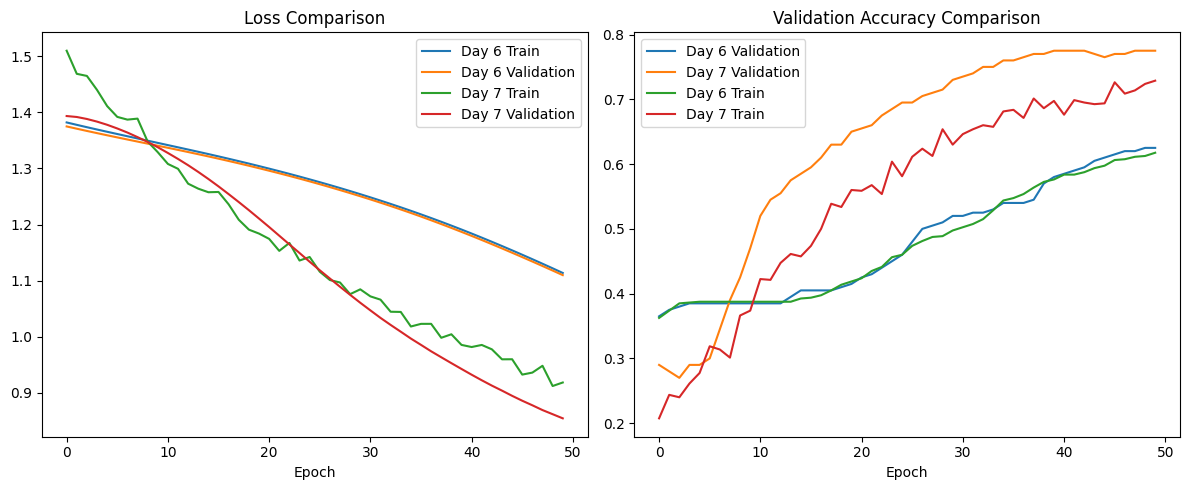

Day 6 Validation Accuracy: 0.625
Day 7 Validation Accuracy: 0.7749999761581421


In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(a_train_losses, label="Day 6 Train")
plt.plot(a_val_losses, label="Day 6 Validation")
plt.plot(b_train_losses, label="Day 7 Train")
plt.plot(b_val_losses, label="Day 7 Validation")
plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(a_val_accs, label="Day 6 Validation")
plt.plot(b_val_accs, label="Day 7 Validation")
plt.plot(a_train_accs, label="Day 6 Train")
plt.plot(b_train_accs, label="Day 7 Train")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

print("Day 6 Validation Accuracy:", a_val_accs[-1])
print("Day 7 Validation Accuracy:", b_val_accs[-1])